In [9]:
from google.colab import files
up = files.upload()
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(0); np.random.seed(0)

Saving sensor-fault-detection.csv to sensor-fault-detection (1).csv


(62629, 3) 0 [1]
count    62629.000000
mean        24.203861
std          5.411599
min          6.886155
25%         21.369419
50%         24.550188
75%         27.443794
max        149.601822
Name: Value, dtype: float64
Timestamp
0 days 00:05:00    59499
0 days 01:00:00     2937
0 days 00:15:00       69
0 days 01:05:00       21
0 days 00:10:00       19
Name: count, dtype: int64


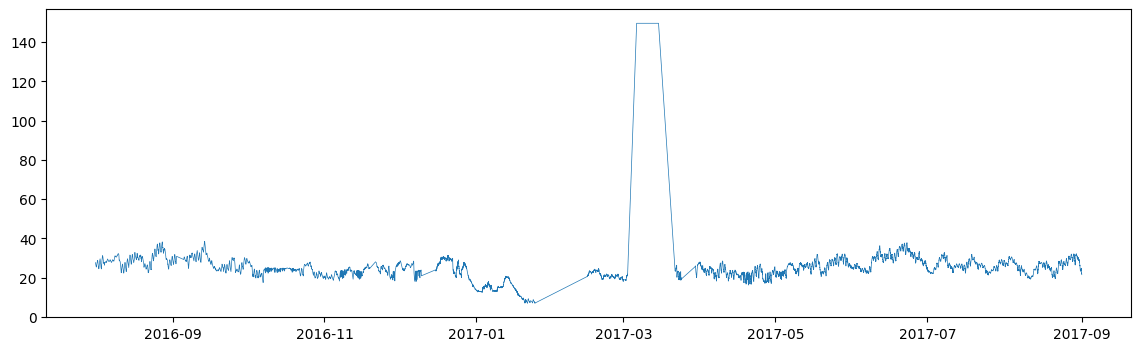

In [10]:
df = pd.read_csv('sensor-fault-detection.csv', sep=';', parse_dates=['Timestamp'])
df = df.sort_values('Timestamp').reset_index(drop=True)
print(df.shape, df.isna().sum().sum(), df.SensorId.unique())
print(df.Value.describe())
print(df.Timestamp.diff().value_counts().head())
plt.figure(figsize=(14,4)); plt.plot(df.Timestamp, df.Value, lw=.5); plt.show()

459 0.007328873205703428


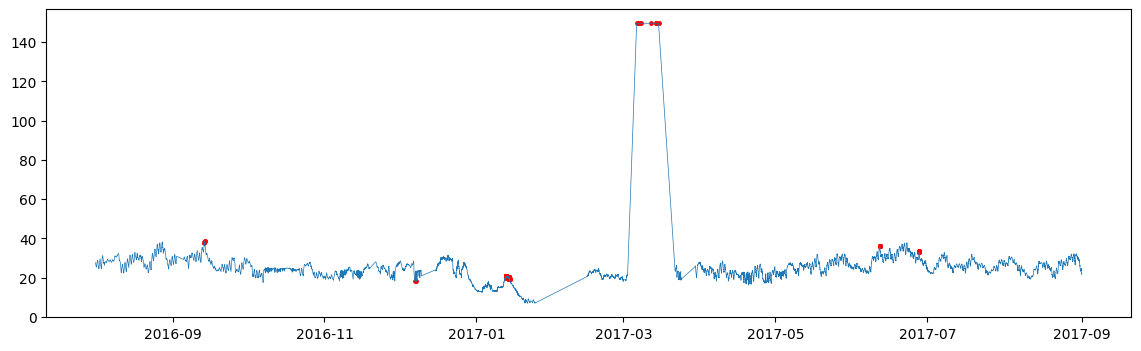

In [11]:
s = df.Value
med = s.rolling(2017, center=True, min_periods=50).median()
mad = (s-med).abs().rolling(2017, center=True, min_periods=50).median().clip(lower=0.5)
z = 0.6745*(s-med)/mad
df['label'] = (z.abs()>4).astype(int)
print(df.label.sum(), df.label.mean())
plt.figure(figsize=(14,4)); plt.plot(df.Timestamp, s, lw=.5)
a=df[df.label==1]; plt.scatter(a.Timestamp, a.Value, c='r', s=6); plt.show()

In [12]:
F = pd.DataFrame({'v': s, 'diff1': s.diff(), 'diff12': s.diff(12),
                  'dev_med': s-med, 'roll_std': s.rolling(12).std(),
                  'roll_mean': s.rolling(12).mean()})
for k in (1,2,3,6,12): F[f'lag{k}'] = s.shift(k)
F = F.bfill().fillna(0); y = df.label.values
idx = np.arange(len(F))
itr, itmp = train_test_split(idx, test_size=.4, random_state=0, stratify=y)
iva, ite = train_test_split(itmp, test_size=.5, random_state=0, stratify=y[itmp])
sc = StandardScaler().fit(F.iloc[itr])
Xtr, Xva, Xte = [sc.transform(F.iloc[i]) for i in (itr, iva, ite)]
ytr, yva, yte = y[itr], y[iva], y[ite]
print(ytr.sum(), yva.sum(), yte.sum())

275 92 92


Epoch 1/100
147/147 - 4s - 24ms/step - accuracy: 0.8844 - loss: 0.5931 - val_accuracy: 0.9949 - val_loss: 0.1944
Epoch 2/100
147/147 - 1s - 6ms/step - accuracy: 0.9515 - loss: 0.2874 - val_accuracy: 0.9957 - val_loss: 0.0728
Epoch 3/100
147/147 - 1s - 6ms/step - accuracy: 0.9739 - loss: 0.1790 - val_accuracy: 0.9926 - val_loss: 0.0537
Epoch 4/100
147/147 - 1s - 6ms/step - accuracy: 0.9708 - loss: 0.1577 - val_accuracy: 0.9932 - val_loss: 0.0376
Epoch 5/100
147/147 - 1s - 6ms/step - accuracy: 0.9772 - loss: 0.1373 - val_accuracy: 0.9946 - val_loss: 0.0307
Epoch 6/100
147/147 - 1s - 6ms/step - accuracy: 0.9796 - loss: 0.1265 - val_accuracy: 0.9938 - val_loss: 0.0263
Epoch 7/100
147/147 - 1s - 8ms/step - accuracy: 0.9822 - loss: 0.1020 - val_accuracy: 0.9952 - val_loss: 0.0235
Epoch 8/100
147/147 - 1s - 10ms/step - accuracy: 0.9849 - loss: 0.1039 - val_accuracy: 0.9954 - val_loss: 0.0212
Epoch 9/100
147/147 - 2s - 10ms/step - accuracy: 0.9845 - loss: 0.0823 - val_accuracy: 0.9956 - val_lo

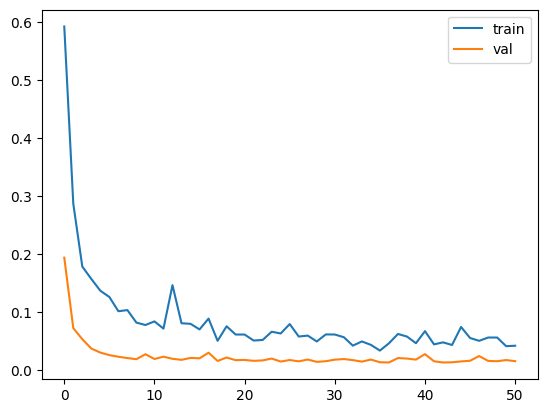

In [13]:
def build(d, units=(128,64,32), drop=0.2, lr=1e-3):
    m = keras.Sequential([keras.Input((d,))])
    for u in units:
        m.add(layers.Dense(u)); m.add(layers.BatchNormalization()); m.add(layers.ReLU()); m.add(layers.Dropout(drop))
    m.add(layers.Dense(1, activation='sigmoid'))
    m.compile(keras.optimizers.Adam(lr), 'binary_crossentropy', metrics=['accuracy'])
    return m
dnn = build(Xtr.shape[1])
w = {0:1., 1:(1-ytr.mean())/ytr.mean()}
h = dnn.fit(Xtr,ytr,validation_data=(Xva,yva),epochs=100,batch_size=256,class_weight=w,
            callbacks=[keras.callbacks.EarlyStopping(patience=8,restore_best_weights=True)],verbose=2)
plt.plot(h.history['loss'],label='train'); plt.plot(h.history['val_loss'],label='val'); plt.legend(); plt.show()

In [14]:
def report(name, yt, yp):
    print(f'{name}: acc={accuracy_score(yt,yp):.4f} P={precision_score(yt,yp,zero_division=0):.3f} R={recall_score(yt,yp):.3f} F1={f1_score(yt,yp):.3f}')
    print(confusion_matrix(yt,yp))
pv = dnn.predict(Xva,verbose=0).ravel()
ths = np.linspace(.05,.95,19); th = ths[np.argmax([f1_score(yva,pv>t,zero_division=0) for t in ths])]
print('threshold', th)
p_dnn = (dnn.predict(Xte,verbose=0).ravel()>th).astype(int)
report('DNN', yte, p_dnn)

threshold 0.85
DNN: acc=0.9982 P=0.829 R=0.946 F1=0.883
[[12416    18]
 [    5    87]]


In [15]:
iso = IsolationForest(contamination=ytr.mean(), random_state=0).fit(Xtr)
p_iso = (iso.predict(Xte)==-1).astype(int); report('IsolationForest', yte, p_iso)
Xn = Xtr[ytr==0]
ae = keras.Sequential([keras.Input((Xtr.shape[1],)), layers.Dense(8,activation='relu'), layers.Dense(3,activation='relu'),
                       layers.Dense(8,activation='relu'), layers.Dense(Xtr.shape[1])])
ae.compile('adam','mse')
ae.fit(Xn,Xn,validation_split=.2,epochs=100,batch_size=256,verbose=0,
       callbacks=[keras.callbacks.EarlyStopping(patience=8,restore_best_weights=True)])
err = lambda X: ((ae.predict(X,verbose=0)-X)**2).mean(1)
ev = err(Xva); ts = np.percentile(ev, np.linspace(80,99.9,60))
t_ae = ts[np.argmax([f1_score(yva, ev>t, zero_division=0) for t in ts])]
p_ae = (err(Xte)>t_ae).astype(int); report('Autoencoder', yte, p_ae)

IsolationForest: acc=0.9852 P=0.020 R=0.022 F1=0.021
[[12338    96]
 [   90     2]]
Autoencoder: acc=0.9554 P=0.135 R=0.935 F1=0.235
[[11881   553]
 [    6    86]]


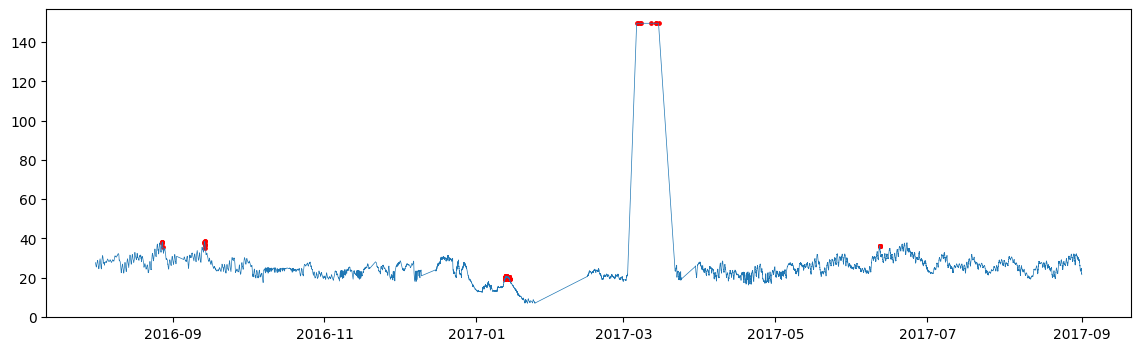

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
pred = (dnn.predict(sc.transform(F),verbose=0).ravel()>th).astype(int)
plt.figure(figsize=(14,4)); plt.plot(df.Timestamp, s, lw=.5)
m = pred==1; plt.scatter(df.Timestamp[m], s[m], c='r', s=6); plt.show()
out = df[['Timestamp','SensorId','Value']].copy(); out['anomaly_pred'] = pred
out.to_csv('anomalies.csv', index=False)
files.download('anomalies.csv')